# Archaic (Shakespeare) – 02 Train & Generation

Fine-tune **SmolLM2-135M** on the blocks from `01_data.ipynb`, and compare generations before and after training.

**Deliverables:** training-loss plot, saved checkpoint, two before/after examples.

## 1. Setup

In [1]:
import math
from pathlib import Path

import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup

In [2]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"
OUT_DIR    = Path("../../results/archaic")     # written by 01_data
SEED       = 42

EPOCHS, BS, LR = 3, 16, 5e-5

PREFIX_1 = "My lord, the night grows long and I am weary,\n"
PREFIX_2 = "My lord,\n"

device: cuda


## 2. Load data, model and tokenizer

In [3]:
lm_data = load_from_disk(OUT_DIR / "blocks")
print(lm_data)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).float().to(device)
print("params:", model.num_parameters())

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'labels'],
        num_rows: 4346
    })
    test: Dataset({
        features: ['input_ids', 'labels'],
        num_rows: 425
    })
})


model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

params: 134515008


## 3. Before training: generation

In [4]:
gen_kwargs = dict(
    max_new_tokens=120,
    do_sample=True,
    temperature=0.8,
    top_p=0.9,
    pad_token_id=tokenizer.eos_token_id,
)

def generate_text(m, prefix, seed=SEED):
    m.eval()
    with torch.inference_mode():
        enc = tokenizer(prefix, return_tensors="pt").to(device)
        torch.manual_seed(seed)
        out = m.generate(**enc, **gen_kwargs)
    return tokenizer.decode(out[0])

In [5]:
before_1 = generate_text(model, PREFIX_1)
before_2 = generate_text(model, PREFIX_2)
print(before_1, "\n" + "=" * 60 + "\n" + before_2)

My lord, the night grows long and I am weary,
And the sun is cold and the wind blows and I am afraid,
And the earth is dark, and the trees are withered,
And the green earth is scorched with the sun's heat,
And I have no food, and I have no water,
For now, my soul is sick and my heart is broken;
And all the gods have ceased to worship me,
And the great gods, who are dead, have no longer
Called to me, and I have no gods to call on;
And all the gods who were my friends and my friends 
My lord,
you and all your company
To the sea and to the world
And all the earth,

"My lord,
The sea and the world
Are the people who
Will have to suffer
All the way through
The day
When I shall have
Calm my troubled heart,
And give the world
Peace and joy,

"My lord,
The sea and the world
Are the people who
Will have to suffer
All the way through
The day
When I shall have
Calm my troubled heart,
And give the world
Peace


## 4. Fine-tune

In [6]:
torch.manual_seed(SEED)

lm_data.set_format("torch", columns=["input_ids", "labels"])
train_loader = DataLoader(lm_data["train"], batch_size=BS, shuffle=True)
test_loader  = DataLoader(lm_data["test"],  batch_size=BS)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
sched = get_cosine_schedule_with_warmup(opt, int(0.03 * total_steps), total_steps)

@torch.no_grad()
def evaluate():
    model.eval()
    tot, n = 0.0, 0
    for b in test_loader:
        ids, lab = b["input_ids"].to(device), b["labels"].to(device)
        tot += model(input_ids=ids, labels=lab).loss.item() * ids.size(0)
        n += ids.size(0)
    model.train()
    return tot / n

In [7]:
v = evaluate()
print(f"before training | val loss {v:.4f} | ppl {math.exp(v):.2f}")

log_steps, log_losses, val_losses = [], [], []
step = 0
model.train()
for epoch in range(1, EPOCHS + 1):
    for b in train_loader:
        ids, lab = b["input_ids"].to(device), b["labels"].to(device)
        loss = model(input_ids=ids, labels=lab).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); opt.zero_grad(set_to_none=True)

        step += 1
        if step == 1 or step % 25 == 0:
            log_steps.append(step); log_losses.append(loss.item())
            print(f"step {step}/{total_steps} | loss {loss.item():.4f}")

    v = evaluate()
    val_losses.append(v)
    print(f"epoch {epoch} | val loss {v:.4f} | ppl {math.exp(v):.2f}")
    ckpt_dir = OUT_DIR / f"ckpt_epoch{epoch}"
    model.save_pretrained(ckpt_dir)
    tokenizer.save_pretrained(ckpt_dir)

before training | val loss 3.7319 | ppl 41.76


step 1/816 | loss 3.7646


step 25/816 | loss 3.5761


step 50/816 | loss 3.5657


step 75/816 | loss 3.5239


...

step 750/816 | loss 3.2473


step 775/816 | loss 3.2587


step 800/816 | loss 3.2578


epoch 3 | val loss 3.4477 | ppl 31.43


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

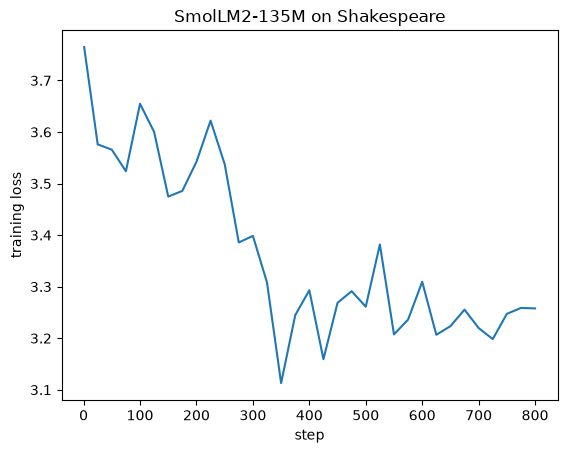

In [8]:
plt.plot(log_steps, log_losses)
plt.xlabel("step"); plt.ylabel("training loss"); plt.title("SmolLM2-135M on Shakespeare")
plt.savefig(OUT_DIR / "train_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Reload the best checkpoint

In [9]:
best_epoch = min(range(len(val_losses)), key=lambda i: val_losses[i]) + 1
ckpt = OUT_DIR / f"ckpt_epoch{best_epoch}"
print("best:", ckpt, "| val loss", round(val_losses[best_epoch - 1], 4))

tuned = AutoModelForCausalLM.from_pretrained(ckpt).to(device)

best: ../../results/archaic/ckpt_epoch2 | val loss 3.4435


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

## 6. After training: generation

In [10]:
after_1 = generate_text(tuned, PREFIX_1)
after_2 = generate_text(tuned, PREFIX_2)

for name, b, a in [("prefix 1", before_1, after_1), ("prefix 2", before_2, after_2)]:
    print(f"##### {name} — BEFORE #####\n{b}\n")
    print(f"##### {name} — AFTER #####\n{a}\n")

##### prefix 1 — BEFORE #####
My lord, the night grows long and I am weary,
And the sun is cold and the wind blows and I am afraid,
And the earth is dark, and the trees are withered,
And the green earth is scorched with the sun's heat,
And I have no food, and I have no water,
For now, my soul is sick and my heart is broken;
And all the gods have ceased to worship me,
And the great gods, who are dead, have no longer
Called to me, and I have no gods to call on;
And all the gods who were my friends and my friends

##### prefix 1 — AFTER #####
My lord, the night grows long and I am weary,
And the sun is cold and heavy.

I am afraid, madam,
I am afraid, and so am I.

O, for my good health,
To have so many dangers to do!

Ay, madam, and yet, for my good health,
You shall have none of them.

Why, madam, what's the matter?

A great deal of grief, sir, for I have a daughter
To have a husband, and so have you, madam.

O, a great deal, madam!

##### prefix 2 — BEFORE #####
My lord,
you and all yo

## 7. Observations

- **Speaker names / stage directions:** none in the provided data (see `01_data.ipynb`).
- **Settings:** seed 42, `max_new_tokens=120`, temperature 0.8, top-p 0.9; identical before and after.
- **Loss:** before training val loss = ..., best epoch = ..., val loss = ...
- **Before vs after:** ...
- **Limitations:** one sample per prefix (single seed).